# 04 · 모델링 — 개선 실험

03_baseline에서 만든 기준선을 바탕으로, Val 오분류 분석에서 나온 가설 하나를 골라 개선 실험을 합니다.

**03과 같은 조건이 보장되는 방법**
- 전처리·Dataset: `src/common.py` (02에서 확정)
- 학습·평가 함수와 기준선 조건: `src/train_utils.py` (03의 함수를 그대로 옮김)
- 04에서는 `get_config("기준선 이름", name="새 이름", 바꿀항목=값)`으로 **바꿀 항목만** 고칩니다. 바꾼 내용은 결과 파일(`summary_*.json`의 `changed_from_baseline`)에 자동으로 남습니다.

**Test는 이 노트북에서도 아직 사용하지 않습니다.** (규칙 3: 최종 모델 확정 후 한 번만 평가)

## 00 · 기본 설정

In [ ]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch

# ── 프로젝트 최상위 폴더를 찾아 src를 불러올 수 있게 함 ──
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.common import (
    DATA_DIR, MODEL_DIR, RESULT_DIR, FIGURE_DIR,   # 폴더 경로
    SEED, IMG_SIZE, BATCH_SIZE,                    # 02에서 확정한 설정값
    ResizePad, eval_transform, train_transform,    # 02에서 확정한 전처리
    ActionDataset, load_metadata, load_class_names,
)
from src.train_utils import (
    DEVICE, GPU_NAME, SEEDS, BASELINE_EXPERIMENTS,   # 장치, Seed 목록, 기준선 조건
    get_config, build_model, freeze_bn_of_frozen_layers, count_params,
    run_experiment, run_or_load, load_run, predict_saved_run,
    evaluate, make_eval_loader, check_frozen, plot_history, comparison_table,
    load_checkpoint,
)

# ── 데이터: 03과 똑같이 Train/Val만 불러옴 ──
meta = load_metadata()
class_names, class_names_ko = load_class_names()   # 0~7번 순서의 클래스명
NUM_CLASSES = len(class_names)

train_df = meta[meta["split"] == "train"].reset_index(drop=True)
val_df = meta[meta["split"] == "val"].reset_index(drop=True)
assert len(train_df) == 640 and len(val_df) == 160, "분할 장수가 02와 다릅니다"

train_set = ActionDataset(train_df, train_transform)   # 기준선: 증강 없음
val_set = ActionDataset(val_df, eval_transform)        # Val은 항상 고정 전처리 (규칙 7)

print("PyTorch", torch.__version__, "| 장치:", GPU_NAME)
print("Train", len(train_set), "장 | Val", len(val_set), "장 | Seed 목록:", SEEDS)

PyTorch 2.10.0+cu128 | 장치: NVIDIA GeForce RTX 5060 Laptop GPU
Train 640 장 | Val 160 장 | Seed 목록: [42, 43, 44]


## 01 · src로 옮긴 코드 검증

03의 함수를 `src/train_utils.py`로 옮기는 과정에서 무언가 달라지지 않았는지 두 단계로 확인합니다. **이 확인이 통과해야** 04의 결과를 03 기준선과 비교할 자격이 생깁니다.

**1단계 · 모델 구조 점검** — 방식별 학습 가능 파라미터 수와 고정 BN 개수가 03과 같은지 봅니다.

In [ ]:
# 03에서 확인한 값 (학습 가능 파라미터, 고정 BN 개수)
expected = {"scratch": (11_180_616, 0), "feature_extraction": (4_104, 20), "fine_tuning": (8_397_832, 15)}

rows = []
for name in BASELINE_EXPERIMENTS:
    m = build_model(get_config(name), NUM_CLASSES)
    m.train()
    n_bn_frozen = freeze_bn_of_frozen_layers(m)
    _, trainable = count_params(m)
    rows.append({"방식": name, "학습 가능 파라미터": f"{trainable:,}", "고정 BN": n_bn_frozen,
                 "03과 같음": "✔" if (trainable, n_bn_frozen) == expected[name] else "✘ 확인 필요"})
    del m
display(pd.DataFrame(rows))

,방식,학습 가능 파라미터,고정 BN,03과 같음
0,scratch,"11,180,616",0,✔
1,feature_extraction,"4,104",20,✔
2,fine_tuning,"8,397,832",15,✔


**2단계 · 재현성 점검** — 가장 빠른 Feature Extraction seed 42를 src 코드로 다시 학습해, 03에서 저장한 결과와 비교합니다(약 2분).

- `save=False`로 실행하므로 03의 결과 파일은 건드리지 않습니다.
- 비교 대상: epoch별 기록(손실·정확도·F1), 최고 Val Macro F1·최고 epoch·중단 epoch, 최고 시점 가중치(BN 기록장 포함 모든 값)
- FE를 고른 이유: 가장 빠르고, 백본을 거꾸로 지나는 계산(역전파)이 없어 GPU의 미세한 계산 순서 차이가 끼어들 여지가 가장 적습니다. 따라서 여기서 차이가 나면 '옮기는 과정의 실수'일 가능성이 높습니다.

In [ ]:
REF = "feature_extraction_seed42"

# ── 03에서 저장한 결과 불러오기 ──
old_hist = pd.read_csv(RESULT_DIR / f"history_{REF}.csv", encoding="utf-8-sig")
with open(RESULT_DIR / f"summary_{REF}.json", encoding="utf-8") as f:
    old_summary = json.load(f)
old_state = load_checkpoint(MODEL_DIR / f"{REF}.pt")["state_dict"]

# ── src 코드로 같은 조건 다시 학습 (파일 저장 안 함) ──
model, new_hist, new_summary = run_experiment(get_config("feature_extraction"), 42,
                                              train_set, val_set, val_df, class_names,
                                              save=False, verbose=False)

# ── 비교 1: epoch별 기록 ──
cols = ["train_loss", "train_accuracy", "val_loss", "val_accuracy", "val_macro_f1"]
same_epochs = len(new_hist) == len(old_hist)
hist_diff = (new_hist[cols] - old_hist[cols]).abs().max().max() if same_epochs else float("nan")

# ── 비교 2: 최고 시점 가중치 (모든 값의 차이 중 가장 큰 것) ──
new_state = {k: v.cpu() for k, v in model.state_dict().items()}
weight_diff = max((new_state[k].double() - old_state[k].double()).abs().max().item() for k in old_state)

# ── 비교 3: 요약 숫자 ──
keys = {"best_val_macro_f1": "최고 Val Macro F1", "best_epoch": "최고 epoch", "stopped_epoch": "중단 epoch"}
check = pd.DataFrame([{"항목": label, "03": old_summary[k], "src": new_summary[k],
                       "같음": "✔" if old_summary[k] == new_summary[k] else "✘"} for k, label in keys.items()])
display(check)
print(f"epoch 수 같음: {same_epochs} | epoch별 기록 최대 차이: {hist_diff:.2e} | 가중치 최대 차이: {weight_diff:.2e}")
print(f"학습 시간: 03 {old_summary['total_time_sec']}초 / src {new_summary['total_time_sec']}초 (시간은 달라도 정상)")

summary_same = all(old_summary[k] == new_summary[k] for k in keys)
if same_epochs and hist_diff < 1e-12 and weight_diff < 1e-12:
    print("✔ 완전 일치: src 코드는 03과 같은 결과를 냅니다.")
elif summary_same:
    print("△ 요약 숫자는 같지만 아주 작은 차이가 있습니다. 차이 크기를 기록해 두고 멘토와 확인하세요.")
else:
    print("✘ 결과가 다릅니다. 04로 넘어가기 전에 원인을 찾아야 합니다.")

del model
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

[안내] feature_extraction_seed42.pt: 안전 모드로 읽을 수 없어 일반 모드로 읽습니다 (직접 저장한 파일이라 괜찮음).


,항목,03,src,같음
0,최고 Val Macro F1,0.8765,0.8765,✔
1,최고 epoch,17.0000,17.0000,✔
2,중단 epoch,30.0000,30.0000,✔


epoch 수 같음: True | epoch별 기록 최대 차이: 0.00e+00 | 가중치 최대 차이: 0.00e+00
학습 시간: 03 116.6초 / src 115.6초 (시간은 달라도 정상)
✔ 완전 일치: src 코드는 03과 같은 결과를 냅니다.


**기록할 것** · 위 출력(일치 여부와 최대 차이)을 보고서의 '실험 환경·재현성' 부분에 한 줄로 남깁니다.
예: "학습 코드를 공용 모듈로 옮긴 뒤 Feature Extraction seed 42를 재실행하여, epoch별 기록과 최종 가중치가 03 결과와 일치함을 확인하였다."

## 02 · Val 오분류 분석 (seed 3개 × FE·FT)

seed 42 하나만 보면 우연한 오류와 모델의 진짜 약점을 구분하기 어렵습니다. 그래서 FE·FT를 seed 3개씩, 총 6개 실행의 Val 예측(160장 × 6 = 960개)을 함께 봅니다. Scratch는 개선 대상이 아니라서 제외합니다.

| 분석 | 질문 | 결과 파일 |
|---|---|---|
| 02-1 | 어떤 혼동이 seed와 상관없이 반복되나? | `figures/14_val_confusion_seedsum.png`, `results/val_confusion_pairs.csv` |
| 02-2 | 어떤 이미지를 반복해서 틀리나? | `figures/15_val_hard_images.png`, `results/val_error_frequency.csv` |
| 02-3 | EDA 가설(점프↔달리기, 여백 모양)이 맞나? | 표 출력 |
| 02-4 | 고질적 오류 이미지에 직접 원인 표시 | `results/val_hard_tagging.csv` (직접 채움) |
| 02-5 | 틀린 이미지는 어떤 Train 이미지와 비슷한가? (배경 단서 점검) | `figures/16_val_hard_neighbors.png` |

**순서 주의**: 02-4의 직접 표시를 **마친 뒤에** 02-5를 실행하세요. 비슷한 Train 이미지를 먼저 보면 "배경이 비슷함"에 체크하고 싶어지는 쪽으로 판단이 기울 수 있습니다.

### 02-0 · 6개 실행의 예측 모으기

03에서 저장한 가중치를 불러와 Val 예측만 다시 뽑습니다(학습 없음, 1분 이내). 다시 계산한 Macro F1이 03의 summary 값과 같으면 올바르게 불러온 것입니다.

In [ ]:
from PIL import Image
from torch import nn
from torchvision.models import resnet18
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support
from src.common import WEIGHTS

METHODS = ["feature_extraction", "fine_tuning"]          # 분석 대상 (Scratch 제외)
SHORT = {"feature_extraction": "FE", "fine_tuning": "FT"}
N_RUNS = len(METHODS) * len(SEEDS)                       # 6개 실행

frames, check_rows = [], []
for name in METHODS:
    for seed in SEEDS:
        path = RESULT_DIR / f"val_predictions_{name}_seed{seed}.csv"
        if path.exists():                                 # 이미 만든 적 있으면 파일에서 읽기
            frame = pd.read_csv(path, encoding="utf-8-sig")
        else:                                             # 없으면 저장된 가중치로 예측해서 저장
            frame = predict_saved_run(name, seed, val_set, val_df, class_names)
        # 확인: 다시 계산한 Macro F1이 03에서 기록한 값과 같은지
        _, _, s = load_run(name, seed, NUM_CLASSES, with_model=False)
        f1 = f1_score(frame["target_id"], frame["pred_id"], average="macro",
                      labels=list(range(NUM_CLASSES)), zero_division=0)
        check_rows.append({"실행": f"{SHORT[name]} seed {seed}", "03 기록": s["best_val_macro_f1"],
                           "다시 계산": round(f1, 4),
                           "같음": "✔" if abs(round(f1, 4) - s["best_val_macro_f1"]) < 1e-4 else "✘ 확인 필요"})
        frames.append(frame)
display(pd.DataFrame(check_rows))

preds = pd.concat(frames, ignore_index=True)
preds["correct"] = preds["correct"].astype(bool)
# 03에서 쓴 내용 비율(Padding 후 실제 사진이 차지하는 비율) 붙이기
image_info = pd.read_csv(RESULT_DIR / "image_info.csv", encoding="utf-8-sig")[["image_id", "content_ratio"]]
preds = preds.merge(image_info, on="image_id", how="left")
print(f"예측 {len(preds)}개 = Val {len(val_df)}장 × {N_RUNS}개 실행")

,실행,03 기록,다시 계산,같음
0,FE seed 42,0.8765,0.8765,✔
1,FE seed 43,0.8821,0.8821,✔
2,FE seed 44,0.8906,0.8906,✔
3,FT seed 42,0.8800,0.8800,✔
4,FT seed 43,0.8844,0.8844,✔
5,FT seed 44,0.8978,0.8978,✔


예측 960개 = Val 160장 × 6개 실행


### 02-1 · seed 합산 혼동 행렬과 반복되는 혼동 쌍

방식별로 seed 3개를 합치면 클래스당 60장이 됩니다. 혼동 쌍마다 **몇 개의 seed에서 나타났는지**를 세어, 3개 seed 모두에서 나타난 혼동(우연이 아닐 가능성이 높음)과 1개 seed에서만 나타난 혼동(우연일 수 있음)을 구분합니다.

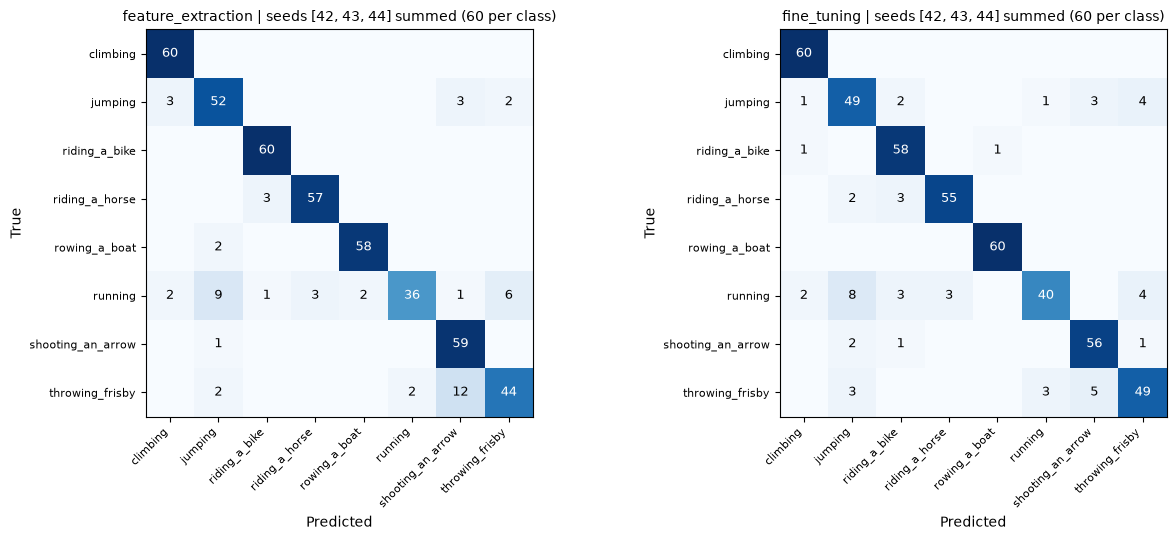

[feature_extraction] 많이 헷갈린 쌍 (합계 상위 8개)


,정답,예측,seed42,seed43,seed44,합계,나타난 seed 수
15,throwing_frisby,shooting_an_arrow,4,4,4,12,3
6,running,jumping,2,3,4,9,3
11,running,throwing_frisby,2,2,2,6,3
0,jumping,climbing,1,1,1,3,3
1,jumping,shooting_an_arrow,1,1,1,3,3
3,riding_a_horse,riding_a_bike,2,0,1,3,2
8,running,riding_a_horse,1,1,1,3,3
2,jumping,throwing_frisby,0,2,0,2,1


[fine_tuning] 많이 헷갈린 쌍 (합계 상위 8개)


,정답,예측,seed42,seed43,seed44,합계,나타난 seed 수
26,running,jumping,3,3,2,8,3
35,throwing_frisby,shooting_an_arrow,1,2,2,5,3
20,jumping,throwing_frisby,1,2,1,4,3
29,running,throwing_frisby,2,1,1,4,3
19,jumping,shooting_an_arrow,1,1,1,3,3
24,riding_a_horse,riding_a_bike,1,0,2,3,2
27,running,riding_a_bike,1,1,1,3,3
28,running,riding_a_horse,1,1,1,3,3


F1                        Recall                 \
방식                     FE             FT             FE             FT   
클래스                                                                      
0 등반         0.96 ± 0.013  0.968 ± 0.013      1.0 ± 0.0      1.0 ± 0.0   
1 점프        0.825 ± 0.029  0.792 ± 0.033  0.867 ± 0.058  0.817 ± 0.029   
2 자전거 타기    0.969 ± 0.035  0.914 ± 0.012      1.0 ± 0.0  0.967 ± 0.029   
3 승마         0.95 ± 0.026  0.931 ± 0.041    0.95 ± 0.05  0.917 ± 0.076   
4 보트 노 젓기   0.967 ± 0.014  0.992 ± 0.014  0.967 ± 0.029      1.0 ± 0.0   
5 달리기       0.735 ± 0.013  0.769 ± 0.008      0.6 ± 0.0  0.667 ± 0.029   
6 활쏘기       0.874 ± 0.013  0.903 ± 0.024  0.983 ± 0.029  0.933 ± 0.029   
7 프리스비 던지기  0.786 ± 0.053  0.831 ± 0.037  0.733 ± 0.058  0.817 ± 0.029   

                Precision                 
방식                     FE             FT  
클래스                                       
0 등반        0.924 ± 0.025  0.938 ± 0.025  
1 점프        0.789 ± 0.035  0.774 ± 0.084  
2 자전거 타기    0.941 ± 0.066  0.867 ± 0.036  
3 승마         0.95 ± 0.003  0.948 ± 0.004  
4 보트 노 젓기   0.967 ± 0.028  0.984 ± 0.027  
5 달리기       0.949 ± 0.044  0.911 ± 0.031  
6 활쏘기       0.787 ± 0.016  0.875 ± 0.026  
7 프리스비 던지기  0.847 ± 0.061  0.846 ± 0.047

In [ ]:
# ── 혼동 행렬 (seed 3개 합산) ──
fig, axes = plt.subplots(1, len(METHODS), figsize=(6.5 * len(METHODS), 5.5))
for ax, name in zip(axes, METHODS):
    sub = preds[preds["experiment"] == name]
    cm = confusion_matrix(sub["target_id"], sub["pred_id"], labels=list(range(NUM_CLASSES)))
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=20 * len(SEEDS))
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            if cm[i, j] > 0:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                        color="white" if cm[i, j] > 30 else "black")
    ax.set_xticks(range(NUM_CLASSES), class_names, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(NUM_CLASSES), class_names, fontsize=8)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(f"{name} | seeds {SEEDS} summed (60 per class)", fontsize=10)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "14_val_confusion_seedsum.png", dpi=120, bbox_inches="tight")
plt.show()

# ── 혼동 쌍: seed별 횟수와 나타난 seed 수 ──
err = preds[~preds["correct"]]
pair_counts = (err.groupby(["experiment", "class_name", "pred_name", "seed"]).size()
               .unstack("seed", fill_value=0).reindex(columns=SEEDS, fill_value=0))
pair_counts.columns = [f"seed{s}" for s in SEEDS]
seed_cols = list(pair_counts.columns)
pair_counts["합계"] = pair_counts[seed_cols].sum(axis=1)
pair_counts["나타난 seed 수"] = (pair_counts[seed_cols] > 0).sum(axis=1)
pair_counts = (pair_counts.reset_index()
               .rename(columns={"class_name": "정답", "pred_name": "예측"})
               .sort_values(["experiment", "합계"], ascending=[True, False]))
pair_counts.to_csv(RESULT_DIR / "val_confusion_pairs.csv", index=False, encoding="utf-8-sig")
for name in METHODS:
    print(f"[{name}] 많이 헷갈린 쌍 (합계 상위 8개)")
    display(pair_counts[pair_counts["experiment"] == name].head(8).drop(columns="experiment"))

# ── 클래스별 성능: seed 3개 평균 ± 표준편차 ──
rows = []
for (name, seed), sub in preds.groupby(["experiment", "seed"]):
    p, r, f, _ = precision_recall_fscore_support(sub["target_id"], sub["pred_id"],
                                                 labels=list(range(NUM_CLASSES)), zero_division=0)
    for i in range(NUM_CLASSES):
        rows.append({"방식": SHORT[name], "클래스": f"{i} {class_names_ko[i]}",
                     "F1": f[i], "Recall": r[i], "Precision": p[i]})
g = pd.DataFrame(rows).groupby(["클래스", "방식"])
fmt = lambda col: g[col].mean().round(3).astype(str) + " ± " + g[col].std().round(3).astype(str)
cls_table = pd.DataFrame({m: fmt(m) for m in ["F1", "Recall", "Precision"]}).unstack("방식")
cls_table.to_csv(RESULT_DIR / "val_per_class_all_seeds.csv", encoding="utf-8-sig")
display(cls_table)

**확인할 것** · "나타난 seed 수"가 3인 혼동 쌍이 FE와 FT 양쪽에 공통으로 있나요? 양쪽 모두에서 3개 seed 내내 나타나는 혼동이 가장 강력한 개선 대상 후보입니다. Recall이 낮은 클래스(놓치는 쪽)와 Precision이 낮은 클래스(다른 클래스를 끌어들이는 쪽)도 구분해서 적어 두세요.

### 02-2 · 이미지별 오류 빈도

Val 160장 각각이 6번의 실행 중 몇 번 틀렸는지 셉니다. `HARD_MIN`(기본 4)번 이상 틀린 이미지를 **고질적 오류**로 보고, 모델이 실제로 본 모습(Padding 적용 후)으로 모아 봅니다.

틀린 횟수별 사진 수


n_wrong,0,1,2,3,4,5,6
사진 수,132,5,3,4,5,2,9


FE에서만 틀린 적 있음 4장 | FT에서만 5장 | 양쪽 모두 19장
클래스별 오류 유형


오류 유형,항상 맞힘,가끔 틀림(1~3),고질적(4~6)
class_name,,,
climbing,20,0,0
jumping,15,2,3
riding_a_bike,18,2,0
riding_a_horse,17,2,1
rowing_a_boat,19,1,0
running,11,2,7
shooting_an_arrow,18,1,1
throwing_frisby,14,2,4


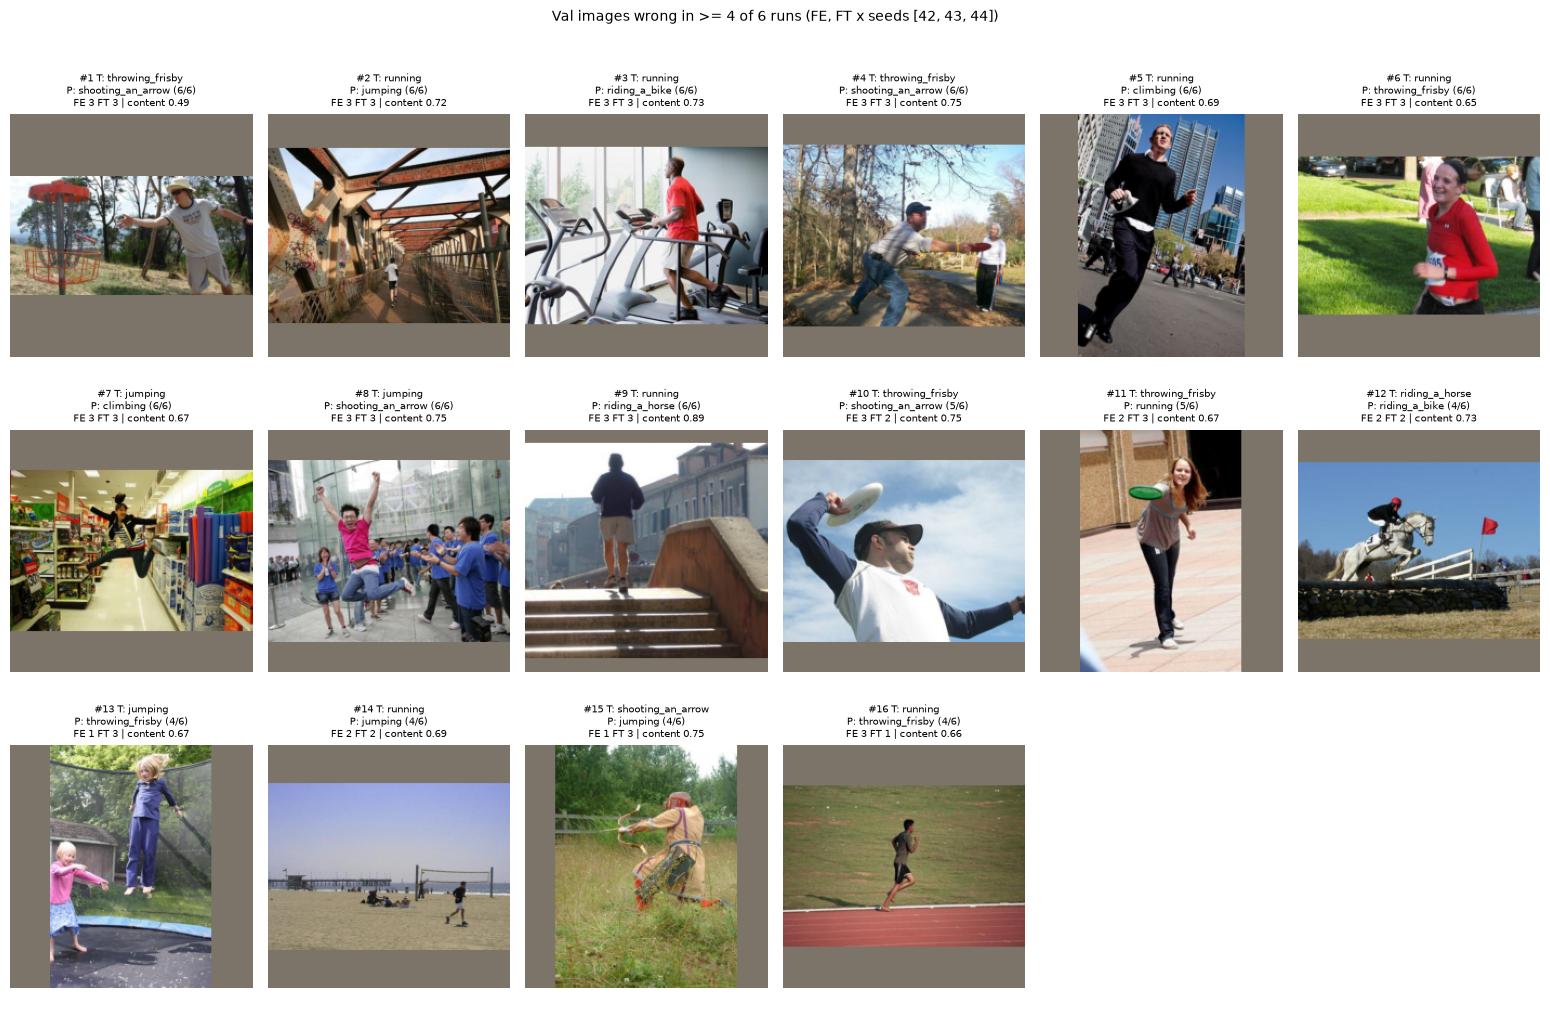

고질적 오류 이미지: 16장


In [ ]:
HARD_MIN = 4   # 6번 중 이 횟수 이상 틀리면 '고질적 오류'

# ── 이미지 한 장 = 한 줄 ──
per_img = preds.groupby("image_id").agg(
    image_path=("image_path", "first"), class_name=("class_name", "first"),
    target_id=("target_id", "first"), content_ratio=("content_ratio", "first"),
    n_wrong=("correct", lambda c: int((~c).sum())),          # 6번 중 틀린 횟수
    true_prob_mean=("true_prob", "mean"),                     # 정답 클래스 확률 평균 (낮을수록 확신 있게 틀림)
)
for name in METHODS:                                          # 방식별 틀린 횟수 (각 0~3)
    per_img[f"n_wrong_{SHORT[name]}"] = (preds[preds["experiment"] == name]
                                         .groupby("image_id")["correct"].apply(lambda c: int((~c).sum())))
per_img["top_wrong_pred"] = err.groupby("image_id")["pred_name"].agg(lambda s: s.value_counts().index[0])
per_img["wrong_preds"] = err.groupby("image_id")["pred_name"].agg(
    lambda s: ", ".join(f"{k} {v}" for k, v in s.value_counts().items()))   # 예: "jumping 4, running 1"
per_img = per_img.reset_index().sort_values(["n_wrong", "true_prob_mean"], ascending=[False, True])
per_img["오류 유형"] = pd.cut(per_img["n_wrong"], bins=[-1, 0, HARD_MIN - 1, N_RUNS],
                           labels=["항상 맞힘", f"가끔 틀림(1~{HARD_MIN - 1})", f"고질적({HARD_MIN}~{N_RUNS})"])
per_img.to_csv(RESULT_DIR / "val_error_frequency.csv", index=False, encoding="utf-8-sig")

# ── 분포 요약 ──
print("틀린 횟수별 사진 수")
display(per_img["n_wrong"].value_counts().reindex(range(N_RUNS + 1), fill_value=0).rename("사진 수").to_frame().T)
fe_only = ((per_img["n_wrong_FE"] > 0) & (per_img["n_wrong_FT"] == 0)).sum()
ft_only = ((per_img["n_wrong_FT"] > 0) & (per_img["n_wrong_FE"] == 0)).sum()
both = ((per_img["n_wrong_FE"] > 0) & (per_img["n_wrong_FT"] > 0)).sum()
print(f"FE에서만 틀린 적 있음 {fe_only}장 | FT에서만 {ft_only}장 | 양쪽 모두 {both}장")
print("클래스별 오류 유형")
display(pd.crosstab(per_img["class_name"], per_img["오류 유형"]))

# ── 고질적 오류 이미지 모아 보기 ──
hard = per_img[per_img["n_wrong"] >= HARD_MIN].reset_index(drop=True)
hard.insert(0, "no", range(1, len(hard) + 1))                # 02-4 표시 시트와 같은 번호
pad = ResizePad(IMG_SIZE)

if len(hard) == 0:
    print(f"{HARD_MIN}번 이상 틀린 이미지가 없습니다. HARD_MIN을 낮춰 보세요.")
else:
    n_cols = 6
    n_rows = int(np.ceil(len(hard) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.6 * n_cols, 3.4 * n_rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, row in zip(axes.flat, hard.itertuples()):
        with Image.open(DATA_DIR / row.image_path) as img:
            ax.imshow(pad(img.convert("RGB")))                  # 모델이 본 모습 그대로
        ax.set_title(f"#{row.no} T: {row.class_name}\nP: {row.top_wrong_pred} ({row.n_wrong}/{N_RUNS})\n"
                     f"FE {row.n_wrong_FE} FT {row.n_wrong_FT} | content {row.content_ratio:.2f}", fontsize=7)
    plt.suptitle(f"Val images wrong in >= {HARD_MIN} of {N_RUNS} runs (FE, FT x seeds {SEEDS})", fontsize=10, y=1.01)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "15_val_hard_images.png", dpi=120, bbox_inches="tight")
    plt.show()
print(f"고질적 오류 이미지: {len(hard)}장")

**확인할 것** · 고질적 오류가 특정 클래스에 몰려 있나요? "가끔 틀림"이 많고 "고질적"이 적다면, 오류의 상당 부분이 seed에 따른 흔들림이라는 뜻이므로 개선 실험에서도 큰 폭의 향상을 기대하기 어렵습니다. 이 점도 (3)의 판단 기준을 정할 때 반영합니다.

### 02-3 · EDA 가설 점검: 점프↔달리기, 여백 모양

- **점프↔달리기**: 두 방향을 따로 셉니다. 한쪽 방향만 많다면 "서로 헷갈린다"가 아니라 "한 클래스가 다른 클래스로 흡수된다"는 뜻입니다.
- **여백 모양**: 내용 비율(content_ratio)이 낮은, 즉 길쭉해서 Padding이 많이 붙은 사진에서 더 많이 틀리는지 봅니다. 그룹별 사진 수가 적으면 차이를 단정하지 않습니다.

In [ ]:
# ── 점프↔달리기 방향별 횟수 ──
jr_rows = []
for name in METHODS:
    for seed in SEEDS:
        sub = preds[(preds["experiment"] == name) & (preds["seed"] == seed)]
        is_ = lambda t, p: int(((sub["class_name"] == t) & (sub["pred_name"] == p)).sum())
        jr_rows.append({"방식": SHORT[name], "seed": seed,
                        "달리기→점프": is_("running", "jumping"), "점프→달리기": is_("jumping", "running"),
                        "달리기 오분류 전체": int(((sub["class_name"] == "running") & ~sub["correct"]).sum()),
                        "점프 오분류 전체": int(((sub["class_name"] == "jumping") & ~sub["correct"]).sum())})
jr = pd.DataFrame(jr_rows)
display(jr)
display(jr.groupby("방식")[["달리기→점프", "점프→달리기", "달리기 오분류 전체", "점프 오분류 전체"]].sum())

# ── 내용 비율 그룹별 정답률 (03의 구간 그대로) ──
preds["content_group"] = pd.cut(preds["content_ratio"], bins=[0, 0.6, 0.8, 1.0],
                                labels=["<0.6 (매우 길쭉)", "0.6~0.8", "≥0.8 (정사각형에 가까움)"])
ratio_table = (preds.groupby(["content_group", "experiment"], observed=False)
               .agg(사진수=("image_id", "nunique"), 정답률=("correct", "mean"))
               .round(3).unstack("experiment"))
display(ratio_table)

,방식,seed,달리기→점프,점프→달리기,달리기 오분류 전체,점프 오분류 전체
0,FE,42,2,0,8,2
1,FE,43,3,0,8,4
2,FE,44,4,0,8,2
3,FT,42,3,0,7,3
4,FT,43,3,0,7,4
5,FT,44,2,1,6,4


,달리기→점프,점프→달리기,달리기 오분류 전체,점프 오분류 전체
방식,,,,
FE,9,0,24,8
FT,8,1,20,11


사진수                            정답률            
experiment       feature_extraction fine_tuning feature_extraction fine_tuning
content_group                                                                 
<0.6 (매우 길쭉)                     10          10              0.900       0.900
0.6~0.8                         125         125              0.872       0.877
≥0.8 (정사각형에 가까움)                 25          25              0.960       0.947

**확인할 것** · 내용 비율 그룹 사이 정답률 차이가 몇 장에 해당하는지 계산해 보세요. 예를 들어 사진이 15장뿐인 그룹이라면 정답률 0.05 차이는 seed 3개 합산 45개 예측 중 약 2개 차이에 불과합니다.

### 02-4 · 고질적 오류 이미지에 원인 직접 표시하기

아래 셀은 `results/val_hard_tagging.csv`라는 빈 표시 시트를 만듭니다. **이미 파일이 있으면 덮어쓰지 않습니다**(직접 채운 내용 보호).

**표시 방법**
1. 15번 그림(`figures/15_val_hard_images.png`)에서 번호(#)를 보고, 시트의 같은 `no` 줄에 표시합니다. 필요하면 `image_path`로 원본 사진도 엽니다.
2. 해당하는 항목 칸에 `1`을 적고, 아니면 비워 둡니다. 여러 항목에 동시에 해당할 수 있습니다.
3. 판단 기준은 **"사람이 이 사진을 볼 때 무엇이 정답 판단을 어렵게 하는가"**입니다.

| 항목 | 의미 |
|---|---|
| 사람_작음 | 사진에서 사람이 차지하는 부분이 작음 |
| 도구_작거나_안보임 | 원반·활·노·자전거·말 등 행동을 알려주는 물체가 작거나 가려짐 |
| 자세_유사 | 사람의 자세만 보면 예측된 클래스로 보일 만함 |
| 배경_유사 | 배경이 예측된 클래스에서 흔히 보이는 장면임 |
| 사람도_애매 | 사람이 봐도 정답이 무엇인지 애매하거나 라벨이 의심됨 (라벨은 고치지 않고 기록만) |
| 기타 | 위에 없는 원인. 메모 칸에 내용 적기 |

In [ ]:
TAGS = ["사람_작음", "도구_작거나_안보임", "자세_유사", "배경_유사", "사람도_애매", "기타"]
tag_path = RESULT_DIR / "val_hard_tagging.csv"

if tag_path.exists():
    print(f"이미 있는 파일이라 덮어쓰지 않았습니다: {tag_path.name}")
else:
    sheet = hard[["no", "image_id", "image_path", "class_name", "top_wrong_pred", "wrong_preds", "n_wrong"]].copy()
    for t in TAGS:
        sheet[t] = ""          # 해당하면 1
    sheet["메모"] = ""
    sheet.to_csv(tag_path, index=False, encoding="utf-8-sig")   # 엑셀에서 한글이 깨지지 않는 형식
    print(f"표시 시트를 만들었습니다: {tag_path} ({len(sheet)}장)")

이미 있는 파일이라 덮어쓰지 않았습니다: val_hard_tagging.csv


**표시를 마친 뒤** 아래 셀을 실행해 항목별로 집계합니다.

In [ ]:
tagged = pd.read_csv(tag_path, encoding="utf-8-sig")
marks = tagged[TAGS].apply(pd.to_numeric, errors="coerce").fillna(0)   # 1 이외의 글자는 0으로 처리
if marks.values.sum() == 0:
    print("아직 표시된 항목이 없습니다. val_hard_tagging.csv를 채운 뒤 다시 실행하세요.")
else:
    tagged[TAGS] = marks
    print(f"표시한 이미지 {len(tagged)}장 | 항목별 해당 이미지 수")
    display(marks.sum().astype(int).rename("이미지 수").to_frame().T)
    print("정답 클래스별 항목 수")
    display(tagged.groupby("class_name")[TAGS].sum().astype(int))
    memo = tagged.loc[tagged["메모"].notna(), ["no", "class_name", "top_wrong_pred", "메모"]]
    if len(memo):
        display(memo)

표시한 이미지 16장 | 항목별 해당 이미지 수


,사람_작음,도구_작거나_안보임,자세_유사,배경_유사,사람도_애매,기타
이미지 수,3,1,7,5,0,0


정답 클래스별 항목 수


,사람_작음,도구_작거나_안보임,자세_유사,배경_유사,사람도_애매,기타
class_name,,,,,,
jumping,0,0,2,1,0,0
riding_a_horse,0,0,1,0,0,0
running,3,0,1,3,0,0
shooting_an_arrow,0,0,1,0,0,0
throwing_frisby,0,1,2,1,0,0


### 02-5 · 틀린 이미지와 비슷한 Train 이미지 (배경 단서 점검)

`group_id`는 2,031장이 모두 다른 값(이미지 1장 = 그룹 1개)이라, "촬영 세션 단서" 가설을 group_id로는 확인할 수 없습니다. 대신 이 방법을 씁니다.

1. ImageNet 백본(분류기를 뗀 ResNet18)으로 Train 640장과 Val 160장의 특징(이미지를 요약한 숫자 512개)을 뽑습니다.
2. 고질적 오류 이미지마다 특징이 가장 비슷한 Train 이미지 5장을 찾습니다(코사인 유사도: 두 특징이 같은 방향일수록 1에 가까움).
3. 비슷한 Train 이미지가 **모델이 틀리게 고른 클래스**에 몰려 있는지, 그리고 그 이미지들이 **배경이 비슷해서** 비슷한 것인지 눈으로 확인합니다.

**해석 시 주의**: FE 모델은 바로 이 특징 위에 분류기만 얹은 모델이므로, "이웃이 오답 클래스에 몰려 있다"는 것만으로는 모델이 틀린 이유를 다시 확인한 것에 가깝습니다. 이 분석의 핵심은 2번의 숫자가 아니라 3번, 즉 **왜 비슷한지(배경인지, 자세인지, 구도인지)를 그림으로 확인하는 것**입니다.

비슷한 Train 이미지 5장 중 정답 클래스 / 모델이 고른 오답 클래스 수 (평균)


,사진수,이웃_정답클래스,이웃_오답클래스
오류 유형,,,
항상 맞힘,132,4.48,NaN
가끔 틀림(1~3),12,2.67,1.33
고질적(4~6),16,1.12,2.00


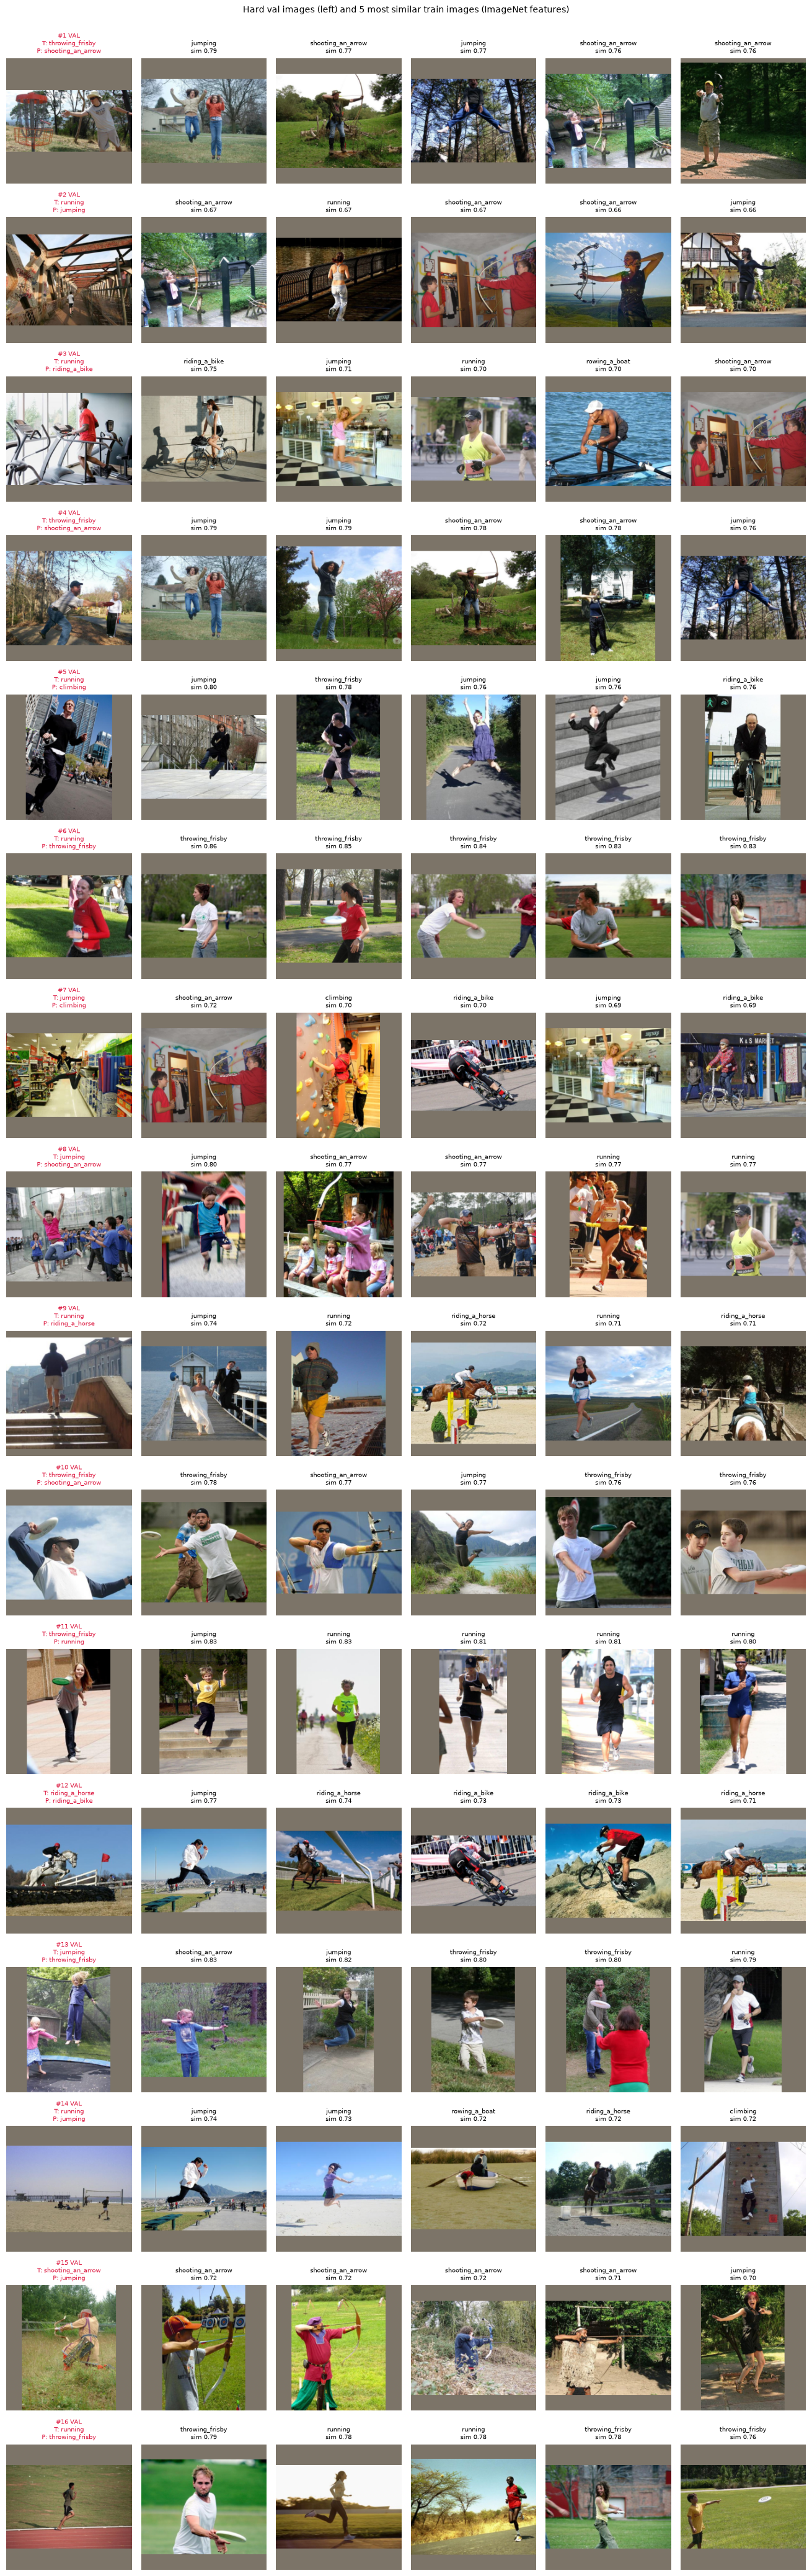

In [ ]:
K = 5   # 이미지마다 찾을 비슷한 Train 이미지 수

# ── ImageNet 백본으로 특징 뽑기 (분류기를 떼고 512개 숫자만 출력) ──
backbone = resnet18(weights=WEIGHTS)
backbone.fc = nn.Identity()
backbone = backbone.to(DEVICE).eval()


@torch.inference_mode()
def extract_features(dataset):
    feats = []
    for images, _ in make_eval_loader(dataset):
        f = backbone(images.to(DEVICE))
        feats.append(nn.functional.normalize(f, dim=1).cpu())   # 길이를 1로 맞춤 → 곱하면 코사인 유사도
    return torch.cat(feats)


train_feats = extract_features(ActionDataset(train_df, eval_transform))   # Train도 고정 전처리로 특징 추출
val_feats = extract_features(val_set)
sim = val_feats @ train_feats.T                                           # Val 160 × Train 640 유사도
topk_sim, topk_idx = (t.numpy() for t in sim.topk(K, dim=1))
del backbone
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

# ── 이미지별 이웃 정보 ──
nb_ids = train_df["target_id"].to_numpy()[topk_idx]                        # 160 × K, 이웃의 클래스 번호
val_pos = {iid: i for i, iid in enumerate(val_df["image_id"])}             # image_id → val_df 행 번호
name_to_id = {c: i for i, c in enumerate(class_names)}
nb_rows = []
for row in per_img.itertuples():
    ids = nb_ids[val_pos[row.image_id]]
    wrong_id = name_to_id.get(row.top_wrong_pred) if isinstance(row.top_wrong_pred, str) else None
    nb_rows.append({"image_id": row.image_id,
                    "nb_true": int((ids == row.target_id).sum()),                         # 이웃 중 정답 클래스 수
                    "nb_wrongpred": int((ids == wrong_id).sum()) if wrong_id is not None else np.nan,  # 이웃 중 오답 클래스 수
                    "nb_classes": ", ".join(class_names[c] for c in ids)})
per_img = per_img.drop(columns=["nb_true", "nb_wrongpred", "nb_classes"], errors="ignore").merge(
    pd.DataFrame(nb_rows), on="image_id")
per_img.to_csv(RESULT_DIR / "val_error_frequency.csv", index=False, encoding="utf-8-sig")   # 이웃 정보 추가해 다시 저장

print(f"비슷한 Train 이미지 {K}장 중 정답 클래스 / 모델이 고른 오답 클래스 수 (평균)")
display(per_img.groupby("오류 유형", observed=False)
        .agg(사진수=("image_id", "size"), 이웃_정답클래스=("nb_true", "mean"), 이웃_오답클래스=("nb_wrongpred", "mean"))
        .round(2))

# ── 그림: 고질적 오류 이미지(왼쪽) + 비슷한 Train 이미지 K장 ──
if len(hard):
    fig, axes = plt.subplots(len(hard), K + 1, figsize=(2.2 * (K + 1), 2.6 * len(hard)), squeeze=False)
    for r, row in enumerate(hard.itertuples()):
        i = val_pos[row.image_id]
        paths = [row.image_path] + list(train_df["image_path"].to_numpy()[topk_idx[i]])
        titles = [f"#{row.no} VAL\nT: {row.class_name}\nP: {row.top_wrong_pred}"] + \
                 [f"{class_names[c]}\nsim {s:.2f}" for c, s in zip(nb_ids[i], topk_sim[i])]
        for c, (ax, path, title) in enumerate(zip(axes[r], paths, titles)):
            with Image.open(DATA_DIR / path) as img:
                ax.imshow(pad(img.convert("RGB")))
            ax.set_title(title, fontsize=7, color="crimson" if c == 0 else "black")
            ax.axis("off")
    plt.suptitle(f"Hard val images (left) and {K} most similar train images (ImageNet features)", fontsize=10, y=1.0)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "16_val_hard_neighbors.png", dpi=100, bbox_inches="tight")
    plt.show()

**확인할 것** · 비슷한 Train 이미지가 오답 클래스에 몰려 있는 경우, 그 이유가 배경(물, 들판, 하늘 등)인지 사람의 자세인지 구도인지 이미지별로 메모해 두세요. "배경이 비슷해서" 오답 클래스 이웃이 많은 이미지가 여럿이면 배경 의존 가설의 근거가 됩니다.

### 02-6 · 여백 방향(가로·세로) 점검

02-3에서 본 내용 비율(content_ratio)은 **짧은 변 ÷ 긴 변**이라, 가로 사진과 세로 사진을 구분하지 못합니다. 그런데 클래스마다 사진 방향의 비율이 크게 다릅니다(예: Train의 보트는 대부분 가로, 달리기는 대부분 세로). 모델이 "여백이 좌우에 있으면(=세로 사진) 달리기"처럼 **여백 방향을 지름길 단서로 배웠는지** 확인합니다.

| 표 | 질문 | 이 가설이 맞다면 |
|---|---|---|
| A | 클래스마다 Train 사진 방향 비율이 얼마나 다른가? | (출발점 확인) |
| B | 클래스·방향별로 Val 정답률과 고질적 오류 수는? | 달리기 가로 사진의 정답률이 세로보다 뚜렷이 낮음 |
| C | 그 클래스에서 **드문 방향**으로 찍힌 사진일수록 더 많이 틀리나? (모든 클래스 합산) | 드문 방향 그룹의 정답률이 낮음 |
| D | 틀릴 때, 그 방향 사진이 많은 클래스 쪽으로 가나? | 예측 클래스의 방향 비율이 다른 오답 후보들의 평균보다 높음 |
| E | 달리기 고질적 오류에서 방향과 "사람_작음"은 어떻게 겹치나? | 사람이 작지 않은 가로 사진도 틀림 |
| F | (02-3에서 미뤄 둔 것) 내용 비율 그룹별 클래스 구성 | (내용 비율 해석 보완) |

**해석 시 주의**: 이 분석은 관찰만 합니다. 가로 사진은 넓은 장면을 담아 사람이 작게 찍히기 쉬운 것처럼, 방향은 다른 특성과 함께 움직입니다. 여기서 "방향과 오류가 관련 있다"는 것까지는 말할 수 있지만, "방향 때문이다"는 이 분석만으로 단정할 수 없습니다. 또 같은 사진을 6번 예측한 것이라 예측 개수가 아니라 **사진 수**를 기준으로 크기를 판단합니다.

이 셀은 02-2, 02-4(표시 시트), 02-5를 실행한 상태에서 실행합니다. 커널을 재시작했다면 00번과 02-0부터 다시 실행하세요(02-5는 다시 실행하지 않아도 됩니다).

In [ ]:
ORIENTS = ["세로", "정사각", "가로"]

def add_orientation(df):
    """가로/세로 길이 비율로 사진 방향을 붙인다. (가로÷세로가 0.95~1.05면 정사각)"""
    r = df["width"] / df["height"]
    out = df.copy()
    out["방향"] = np.select([r > 1.05, r < 0.95], ["가로", "세로"], default="정사각")
    return out

train_o = add_orientation(train_df)
val_o = add_orientation(val_df)[["image_id", "방향"]]

# ── A. 클래스별 Train 사진 방향 비율 ──
train_share = (pd.crosstab(train_o["class_name"], train_o["방향"], normalize="index")
               .reindex(columns=ORIENTS, fill_value=0.0))          # 클래스마다 방향 비율 (합 1)
print("A. 클래스별 Train 사진 방향 비율 (%)")
display((train_share * 100).round(0).astype(int))

# ── 이미지 한 장 = 한 줄 표에 방향 정보 붙이기 ──
img = per_img.merge(val_o, on="image_id")
img["정답클래스_방향비율"] = [train_share.loc[c, o] for c, o in zip(img["class_name"], img["방향"])]
img["acc_all"] = 1 - img["n_wrong"] / N_RUNS          # 6번 중 맞힌 비율
img["acc_FE"] = 1 - img["n_wrong_FE"] / len(SEEDS)
img["acc_FT"] = 1 - img["n_wrong_FT"] / len(SEEDS)
is_hard = lambda s: int((s >= HARD_MIN).sum())

# ── B. 클래스 × 방향별 Val 정답률 ──
tb = (img.groupby(["class_name", "방향"])
      .agg(사진수=("image_id", "size"), FE_정답률=("acc_FE", "mean"), FT_정답률=("acc_FT", "mean"),
           고질적=("n_wrong", is_hard))
      .round(2).reset_index())
tb.to_csv(RESULT_DIR / "val_orientation_by_class.csv", index=False, encoding="utf-8-sig")
print("B. 클래스 × 방향별 Val 정답률 (6개 실행)")
display(tb)

# ── C. 정답 클래스에서 드문 방향일수록 더 틀리나? (모든 클래스 합산) ──
img["방향_흔함"] = pd.cut(img["정답클래스_방향비율"], bins=[-0.01, 0.4, 0.6, 1.0],
                       labels=["드문 방향(<40%)", "중간(40~60%)", "흔한 방향(>60%)"])
tc = (img.groupby("방향_흔함", observed=False)
      .agg(사진수=("image_id", "size"), FE_정답률=("acc_FE", "mean"), FT_정답률=("acc_FT", "mean"),
           고질적=("n_wrong", is_hard))
      .round(3))
print("C. 정답 클래스의 Train에서 그 방향이 차지하는 비율별 정답률")
display(tc)
print("  드문 방향 그룹의 클래스 구성:",
      img.loc[img["방향_흔함"] == "드문 방향(<40%)", "class_name"].value_counts().to_dict())

A. 클래스별 Train 사진 방향 비율 (%)


방향,세로,정사각,가로
class_name,,,
climbing,62,1,36
jumping,51,2,46
riding_a_bike,44,6,50
riding_a_horse,25,5,70
rowing_a_boat,6,1,92
running,66,4,30
shooting_an_arrow,30,4,66
throwing_frisby,42,8,50


B. 클래스 × 방향별 Val 정답률 (6개 실행)


,class_name,방향,사진수,FE_정답률,FT_정답률,고질적
0,climbing,가로,4,1.00,1.00,0
1,climbing,세로,15,1.00,1.00,0
2,climbing,정사각,1,1.00,1.00,0
3,jumping,가로,9,0.78,0.78,2
4,jumping,세로,11,0.94,0.85,1
5,riding_a_bike,가로,10,1.00,0.97,0
6,riding_a_bike,세로,8,1.00,0.96,0
7,riding_a_bike,정사각,2,1.00,1.00,0
8,riding_a_horse,가로,15,0.96,0.93,1
9,riding_a_horse,세로,5,0.93,0.87,0


C. 정답 클래스의 Train에서 그 방향이 차지하는 비율별 정답률


,사진수,FE_정답률,FT_정답률,고질적
방향_흔함,,,,
드문 방향(<40%),32,0.802,0.792,7
중간(40~60%),57,0.860,0.860,7
흔한 방향(>60%),71,0.948,0.958,2


  드문 방향 그룹의 클래스 구성: {'running': 10, 'shooting_an_arrow': 9, 'riding_a_horse': 5, 'climbing': 5, 'riding_a_bike': 2, 'throwing_frisby': 1}


In [ ]:
# ── D. 틀릴 때, 그 방향 사진이 많은 클래스 쪽으로 가나? ──
# 예측 클래스의 방향 비율을 '정답을 뺀 나머지 7개 클래스(오답 후보)'의 평균과 비교한다.
# 방향이 아무 상관 없다면 차이의 평균은 0 근처, 방향을 따라간다면 양수가 된다.
err_o = err.merge(val_o, on="image_id")
cand_mean = []
for t, o in zip(err_o["class_name"], err_o["방향"]):
    others = [c for c in class_names if c != t]                  # 정답을 뺀 오답 후보 7개
    cand_mean.append(train_share.loc[others, o].mean())
err_o["예측클래스_방향비율"] = [train_share.loc[p, o] for p, o in zip(err_o["pred_name"], err_o["방향"])]
err_o["후보평균_방향비율"] = cand_mean
err_o["차이"] = err_o["예측클래스_방향비율"] - err_o["후보평균_방향비율"]

td = (err_o.groupby("experiment")
      .agg(틀린예측수=("image_id", "size"), 관련사진수=("image_id", "nunique"),
           차이_평균=("차이", "mean"), 후보평균보다_높은비율=("차이", lambda s: (s > 0).mean()))
      .round(3))
print("D. 틀린 예측의 방향 비율: 예측 클래스 − 오답 후보 평균")
display(td)

# 고질적 오류 16장만 사진 단위로 (가장 자주 나온 오답 기준)
hard_o = hard.merge(val_o, on="image_id")
hard_o["예측클래스_방향비율"] = [train_share.loc[p, o] for p, o in zip(hard_o["top_wrong_pred"], hard_o["방향"])]
hard_o["정답클래스_방향비율"] = [train_share.loc[c, o] for c, o in zip(hard_o["class_name"], hard_o["방향"])]
hard_o["후보평균_방향비율"] = [train_share.loc[[c for c in class_names if c != t], o].mean()
                            for t, o in zip(hard_o["class_name"], hard_o["방향"])]
show = hard_o[["no", "class_name", "top_wrong_pred", "방향",
               "정답클래스_방향비율", "예측클래스_방향비율", "후보평균_방향비율"]].round(2)
print("고질적 오류 이미지별 방향 비율")
display(show)
print(f"예측 클래스가 후보 평균보다 그 방향 사진이 많은 경우: "
      f"{int((hard_o['예측클래스_방향비율'] > hard_o['후보평균_방향비율']).sum())} / {len(hard_o)}장")

D. 틀린 예측의 방향 비율: 예측 클래스 − 오답 후보 평균


,틀린예측수,관련사진수,차이_평균,후보평균보다_높은비율
experiment,,,,
feature_extraction,54,23,0.041,0.611
fine_tuning,53,24,0.037,0.585


고질적 오류 이미지별 방향 비율


,no,class_name,top_wrong_pred,방향,정답클래스_방향비율,예측클래스_방향비율,후보평균_방향비율
0,1,throwing_frisby,shooting_an_arrow,가로,0.50,0.66,0.56
1,2,running,jumping,가로,0.30,0.46,0.59
2,3,running,riding_a_bike,가로,0.30,0.50,0.59
3,4,throwing_frisby,shooting_an_arrow,가로,0.50,0.66,0.56
4,5,running,climbing,세로,0.66,0.62,0.37
5,6,running,throwing_frisby,가로,0.30,0.50,0.59
6,7,jumping,climbing,가로,0.46,0.36,0.56
7,8,jumping,shooting_an_arrow,가로,0.46,0.66,0.56
8,9,running,riding_a_horse,가로,0.30,0.70,0.59
9,10,throwing_frisby,shooting_an_arrow,가로,0.50,0.66,0.56


예측 클래스가 후보 평균보다 그 방향 사진이 많은 경우: 9 / 16장


In [ ]:
# ── E. 달리기 고질적 오류: 방향과 직접 표시(사람_작음 등) 함께 보기 ──
tagged = pd.read_csv(tag_path, encoding="utf-8-sig")
tagged[TAGS] = tagged[TAGS].apply(pd.to_numeric, errors="coerce").fillna(0).astype(int)
run_tag = (tagged[tagged["class_name"] == "running"]
           .merge(val_o, on="image_id")[["no", "top_wrong_pred", "방향", "사람_작음", "배경_유사", "자세_유사"]])
print("E-1. 달리기 고질적 오류 이미지의 방향과 표시")
display(run_tag)
run_all = img[img["class_name"] == "running"]
print("E-2. Val 달리기 전체: 방향별 사진 수와 고질적 오류 수")
display(run_all.groupby("방향").agg(사진수=("image_id", "size"), 고질적=("n_wrong", is_hard),
                                     평균정답률=("acc_all", "mean")).round(2))

# ── F. 내용 비율 그룹별 클래스 구성 (02-3 보완) ──
img["content_group"] = pd.cut(img["content_ratio"], bins=[0, 0.6, 0.8, 1.0],
                              labels=["<0.6", "0.6~0.8", "≥0.8"])
print("F. 내용 비율 그룹별 Val 클래스 구성 (사진 수)")
display(pd.crosstab(img["class_name"], img["content_group"], margins=True, margins_name="합계"))

E-1. 달리기 고질적 오류 이미지의 방향과 표시


,no,top_wrong_pred,방향,사람_작음,배경_유사,자세_유사
0,2,jumping,가로,1,0,0
1,3,riding_a_bike,가로,0,1,0
2,5,climbing,세로,0,1,0
3,6,throwing_frisby,가로,0,1,0
4,9,riding_a_horse,가로,0,0,1
5,14,jumping,가로,1,0,0
6,16,throwing_frisby,가로,1,0,0


E-2. Val 달리기 전체: 방향별 사진 수와 고질적 오류 수


,사진수,고질적,평균정답률
방향,,,
가로,9,6,0.41
세로,10,1,0.80
정사각,1,0,1.00


F. 내용 비율 그룹별 Val 클래스 구성 (사진 수)


content_group,<0.6,0.6~0.8,≥0.8,합계
class_name,,,,
climbing,0,18,2,20
jumping,1,16,3,20
riding_a_bike,1,13,6,20
riding_a_horse,4,15,1,20
rowing_a_boat,2,17,1,20
running,1,16,3,20
shooting_an_arrow,0,15,5,20
throwing_frisby,1,15,4,20
합계,10,125,25,160


**확인할 것**
- **B·E-2**: 달리기 가로 사진과 세로 사진의 정답률·고질적 오류 수를 비교하세요. 사진 수가 10장 안팎이므로, 차이를 **사진 몇 장**으로 바꿔서 판단합니다.
- **C**: 드문 방향 그룹의 정답률이 흔한 방향 그룹보다 낮나요? 드문 방향 그룹이 한두 클래스로만 이루어져 있다면, 방향 효과와 클래스 효과가 섞여 있다는 뜻입니다.
- **D**: "차이_평균"이 0보다 뚜렷이 크고, "후보평균보다_높은비율"이 절반을 크게 넘나요? 그렇다면 모델이 틀릴 때 방향이 맞는 쪽으로 끌려간다는 근거입니다.
- **E-1**: 달리기 가로 사진 중 사람_작음이 **아닌데도** 틀린 사진이 있나요? 있다면 "사람이 작아서"만으로는 설명되지 않는 부분입니다.

## 02 정리

- **seed와 상관없이 반복되는 혼동**: FE·FT 모두에서 seed 3개 내내 나타난 혼동은 5쌍(달리기→점프·프리스비·승마, 점프→활쏘기, 프리스비→활쏘기)이며, 그중 3쌍의 정답이 달리기였다. 프리스비→활쏘기는 FE 12회 대 FT 5회로 방식 간 차이가 가장 컸고, 이에 따라 활쏘기 Precision도 FE(0.787)가 FT(0.875)보다 낮았다. 즉 이 혼동은 layer4를 학습하면 줄어드는 유형이다.

- **고질적 오류 이미지 수와 몰린 클래스**: 한 번이라도 틀린 Val 이미지 28장 중 16장(57%)이 6회 실행 중 4회 이상 틀렸고, 9장은 매번 틀렸다. 오류가 seed에 따라 흩어지지 않고 특정 이미지에 고정되어 있으며, 28장 중 19장(68%)은 FE와 FT가 모두 틀린 이미지였다. 고질적 오류 16장 중 14장(88%)이 달리기(7), 프리스비 던지기(4), 점프(3)에 몰려 있었다.

- **점프↔달리기 방향**: 달리기→점프는 FE 9회, FT 8회였으나 점프→달리기는 FT seed 44의 1회뿐으로, 혼동은 한쪽 방향에 치우쳐 있었다. 달리기 오분류 중 점프로 간 비율은 FE 38%, FT 40%에 그쳤고, 나머지는 프리스비 던지기·승마·자전거 타기 등으로 흩어졌다. 따라서 "점프와 달리기가 서로 헷갈린다"는 EDA 가설보다 "달리기가 여러 클래스로 흡수된다"가 관찰에 더 가깝다. FE는 seed 3개 모두 달리기 20장 중 8장을 틀렸고 그 대부분이 같은 사진이었는데, 이는 고정된 ImageNet 특징 위에서 분류기만 학습하는 FE의 구조상 오류가 특징에 의해 결정되기 때문으로 해석된다.

- **여백 두께(내용 비율) 영향**: 내용 비율이 가장 낮은 그룹(0.6 미만, 10장)의 정답률은 0.90으로 중간 그룹(0.6~0.8, 125장, 0.87~0.88)보다 낮지 않아, "여백이 두꺼울수록 많이 틀린다"는 경향은 확인되지 않았다. 0.8 이상 그룹(25장)은 정답률 0.95~0.96으로 높았지만, 오류가 특정 사진에 고정되는 점을 고려하면 중간 그룹 대비 사진 약 2장 차이로 우연과 구분하기 어렵다. 0.8 이상 그룹의 클래스 구성은 전체와 비슷하여(쉬운 클래스 비율 60% 대 62.5%), 정답률 차이를 클래스 구성으로 설명할 수도 없었다.

- **여백 방향(가로·세로) 영향**: 여백 방향(가로·세로) 영향: Val 달리기는 가로 사진 9장 중 6장이 고질적 오류였으나 세로 사진은 10장 중 1장뿐이었다(Fisher 검정 p≈0.02, 사후 검정). 그러나 달리기를 제외하면 Train에서 드문 방향으로 찍힌 사진의 정답률(FE 0.97, FT 0.93)이 흔한 방향(0.98)과 비슷했고, 틀린 예측이 가로 사진이 많은 클래스로 쏠리지도 않았다(16장 중 9장). 또한 Train에서 가로·세로가 반반인 점프에서도 가로 사진이 더 많이 틀렸다. 따라서 모델이 여백 방향을 지름길로 학습했다는 근거는 약하며, 가로 사진에 사람이 작거나 달리는 동작이 드러나지 않는 구도가 많은 것이 오류의 주된 원인으로 해석된다.

- **직접 표시에서 가장 많이 나온 원인**: 전체로는 자세 유사(7장)와 배경 유사(5장)가 많았으나, 원인은 클래스별로 갈렸다. 달리기는 표시 7개 중 6개가 사람이 작거나(3) 배경이 다른 클래스와 비슷한(3) 경우로, 동작보다 장면에 끌려가는 오류였다. 프리스비 던지기에서 원반이 작거나 보이지 않는 경우는 1장뿐이어서 "작은 원반 누락" 가설은 약하게만 지지되었다. 독립적으로 수행한 두 번의 표시에서 같은 패턴이 나타났다.

- **비슷한 Train 이미지 분석에서 본 것**: 고질적 오류 이미지의 최근접 Train 이미지 5장 중 모델이 고른 오답 클래스는 평균 2.0장이었다. 오답 클래스 이웃이 3장 이상인 4장 중 2장은 잔디밭에서 달리는 사진이었고, 그 이웃은 대부분 잔디밭 위 프리스비 사진이었다. 이는 달리기→프리스비 혼동이 잔디밭이라는 배경 단서에서 비롯되었을 가능성을 보여준다. 반면 이웃에 예측 클래스가 전혀 없는 경우(#5)도 있어, 모든 오류를 특징 공간의 유사성으로 설명할 수는 없었다.

- 오류는 소수의 사진에 고정되어 있고, 크게 두 갈래다. ① 달리기: 사람이 작거나 동작이 안 보이는 구도에서 장면에 끌려감 ② 프리스비: 팔을 뻗은 자세 때문에 활쏘기로 감(FT에서 크게 줄어듦).

- → 이 결과를 바탕으로 (2) 출발 모델과 (3) 개선 판단 기준을 정한다.